# 02 — Statistical diagnostics (training split only)

Checks the assumptions behind the linear models and the inferential claims we
make about coefficients: multicollinearity (VIF), OLS inference, residual
behaviour (out-of-fold), heteroscedasticity (Breusch-Pagan), Lasso selection
and how much a single feature explains compared with all of them.

The OLS design matrix is built with **the same preprocessor `multiple_lr`
uses** (standardised numeric features + one-hot categoricals with the first
level dropped), so the inference here describes exactly that model. The target
is raw yield in t/ha (notebook 01: no log transform).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make `src` importable when run from notebooks/

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from sklearn.linear_model import lasso_path
from sklearn.model_selection import cross_val_predict
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

from src import config
from src.data import load_split, make_kfold, split_xy
from src.eda import binned_means, top_pearson_feature
from src.features import transformed_frame
from src.models import get_linear_models
from src.plots import axis_label, save_figure

pd.set_option("display.width", 200)
train, _ = load_split()
X, y = split_xy(train)
simple_feature = top_pearson_feature(train)
models = get_linear_models(simple_feature)
multiple_lr = models["multiple_lr"].fit(X, y)
design = transformed_frame(multiple_lr[0], X)  # standardised numeric + drop-first one-hot
Y_LABEL = axis_label(config.TARGET)
ALPHA_LEVEL = 0.05

## 1. Multicollinearity — Variance Inflation Factor

In [2]:
VIF_MODERATE, VIF_SEVERE = 5, 10
numeric_design = sm.add_constant(design[config.NUMERIC_FEATURES])  # VIF needs the constant
vif = pd.DataFrame(
    {
        "feature": config.NUMERIC_FEATURES,
        "vif": [variance_inflation_factor(numeric_design.to_numpy(), i + 1) for i in range(len(config.NUMERIC_FEATURES))],
    }
)
vif["flag"] = np.select([vif["vif"] > VIF_SEVERE, vif["vif"] > VIF_MODERATE], ["severe", "moderate"], "ok")
vif.to_csv(config.TABLES_DIR / "vif.csv", index=False)
vif.round(3)

,feature,vif,flag
0,soil_ph,1.001,ok
1,soil_moisture,1.001,ok
2,nitrogen_content,1.001,ok
3,phosphorus_content,1.002,ok
4,potassium_content,1.001,ok
5,avg_temperature,1.003,ok
6,total_rainfall,1.001,ok
7,sunlight_hours,1.002,ok
8,fertilizer_amount,1.002,ok
9,pesticide_usage,1.001,ok


**Interpretation.** Every VIF is ≈ 1.00 (the minimum possible), so no feature
can be predicted from the others. No flags at 5 or 10. This means each linear
coefficient is estimated independently and its standard error is not inflated,
which is why Ridge and plain OLS gave the same CV scores in Phase 4. (It is
also further evidence for synthetic data: real rainfall and soil moisture
would be correlated.)

## 2. OLS inference

In [3]:
ols = sm.OLS(y, sm.add_constant(design)).fit()
ci = ols.conf_int()
ols_table = pd.DataFrame(
    {"coef": ols.params, "std_err": ols.bse, "t": ols.tvalues, "p_value": ols.pvalues, "ci_low": ci[0], "ci_high": ci[1]}
)
ols_table.to_csv(config.TABLES_DIR / "ols_summary.csv", index_label="term")
print(f"R² = {ols.rsquared:.4f}, adjusted R² = {ols.rsquared_adj:.4f}, n = {int(ols.nobs)}")
ols_table.round(4)

R² = 0.6938, adjusted R² = 0.6921, n = 3840


,coef,std_err,t,p_value,ci_low,ci_high
const,6.2949,0.0346,182.1687,0.0000,6.2272,6.3627
soil_ph,0.0132,0.0103,1.2759,0.2021,-0.0071,0.0335
soil_moisture,0.0682,0.0103,6.6045,0.0000,0.0479,0.0884
nitrogen_content,0.0605,0.0103,5.8596,0.0000,0.0402,0.0807
phosphorus_content,0.0253,0.0103,2.4481,0.0144,0.0050,0.0455
potassium_content,0.0565,0.0103,5.4781,0.0000,0.0363,0.0767
avg_temperature,-0.0627,0.0103,-6.0651,0.0000,-0.0829,-0.0424
total_rainfall,0.2142,0.0103,20.7355,0.0000,0.1939,0.2344
sunlight_hours,0.0273,0.0103,2.6417,0.0083,0.0070,0.0475
fertilizer_amount,0.8793,0.0103,85.1314,0.0000,0.8591,0.8996


**Interpretation.** In-sample R² ≈ 0.69 (adjusted R² almost the same, because
21 terms is small next to 3,840 rows). Numeric coefficients are in **t/ha per
one standard deviation** of the feature, so they are directly comparable:

* `fertilizer_amount` dominates (+0.88 t/ha per SD), then `pesticide_usage`
  (−0.27) and `total_rainfall` (+0.21).
* `soil_moisture`, `nitrogen_content`, `potassium_content` (+) and
  `avg_temperature` (−) have small (≈ 0.06 t/ha per SD) but highly significant
  effects. Their raw correlations with yield were < 0.07 — they only become
  detectable once fertilizer's large effect is accounted for, which shrinks
  the residual noise. This is the difference between marginal and partial
  association.
* `soil_ph` and `irrigation_frequency` are not significant *as linear terms*.
  For pH this does not mean "no effect" — notebook 01 showed an inverted-U
  that a straight line cannot represent.
* Crop, region and season dummies are all near zero; Rice and Wheat reach
  p ≈ 0.04, which does not survive any multiple-testing correction across
  10 dummies.

All associations are observational/associative — the model says yield *goes
with* fertilizer, not that fertilizer *causes* it (and here the "cause" is a
data generator).

## 3. Residual diagnostics for `multiple_lr` (out-of-fold predictions)

Out-of-fold predictions come from `cross_val_predict` with the same 5-fold
split used for model comparison, so each residual is from a model that never
saw that row.

residual mean = 0.0001, std = 0.6409, skew = -0.028, excess kurtosis = 0.058, Jarque-Bera p = 0.596


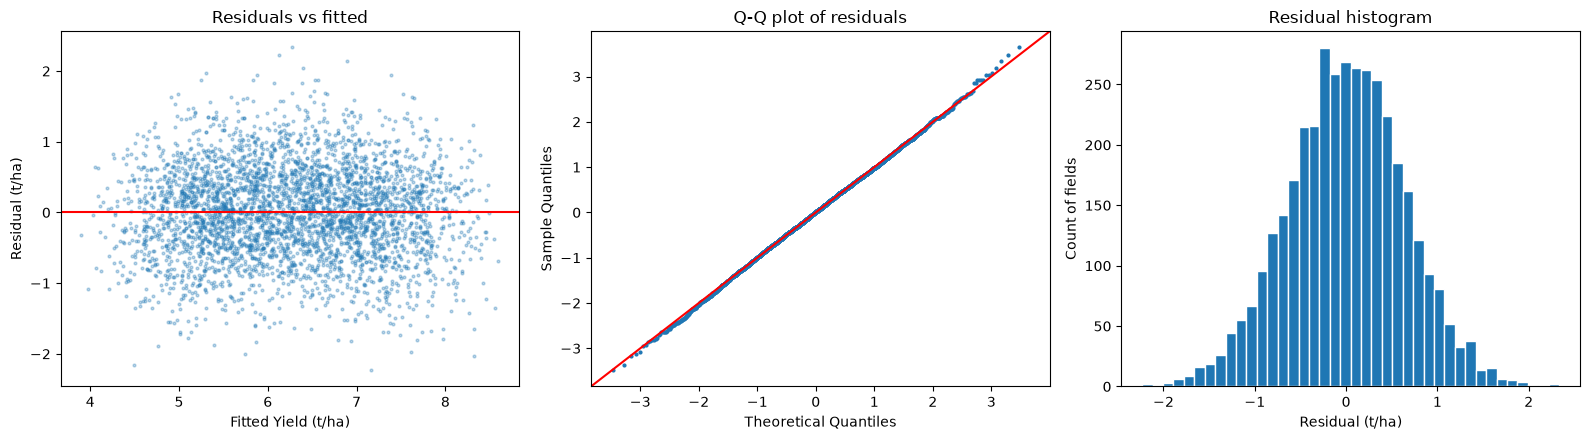

In [4]:
oof_pred = cross_val_predict(models["multiple_lr"], X, y, cv=make_kfold())
resid = y - oof_pred
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(oof_pred, resid, s=4, alpha=0.3)
axes[0].axhline(0, color="red")
axes[0].set(xlabel="Fitted " + Y_LABEL, ylabel="Residual (t/ha)", title="Residuals vs fitted")
sm.qqplot(resid, line="45", fit=True, ax=axes[1], markersize=2)
axes[1].set_title("Q-Q plot of residuals")
axes[2].hist(resid, bins=40, edgecolor="white")
axes[2].set(xlabel="Residual (t/ha)", ylabel="Count of fields", title="Residual histogram")
save_figure(fig, "diag_residuals")
jb = stats.jarque_bera(resid)
print(f"residual mean = {resid.mean():.4f}, std = {resid.std():.4f}, skew = {stats.skew(resid):.3f}, "
      f"excess kurtosis = {stats.kurtosis(resid):.3f}, Jarque-Bera p = {jb.pvalue:.3f}")

**Interpretation.** Residuals form a structureless horizontal band around 0
with no funnel shape; the Q-Q plot follows the 45° line, and the histogram is
bell-shaped (skewness and excess kurtosis both ≈ 0, Jarque-Bera does not
reject normality). The OLS assumptions of normal, zero-mean errors look
satisfied. The residual std (≈ 0.64 t/ha) is the linear model's typical miss.

### Residuals vs features — does the straight line miss curvature?

The top 3 features by |r| are required; every other feature that notebook 01
flagged as curved (Bonferroni-significant quadratic term) is added. The red line is the mean
residual per decile bin; a flat line at 0 means the linear fit captured the
relationship.

Features plotted: ['fertilizer_amount', 'pesticide_usage', 'total_rainfall', 'phosphorus_content', 'soil_ph']


fertilizer_amount    binned mean residual range: -0.144 to +0.103 t/ha
pesticide_usage      binned mean residual range: -0.053 to +0.073 t/ha
total_rainfall       binned mean residual range: -0.129 to +0.085 t/ha
phosphorus_content   binned mean residual range: -0.056 to +0.049 t/ha
soil_ph              binned mean residual range: -0.099 to +0.131 t/ha


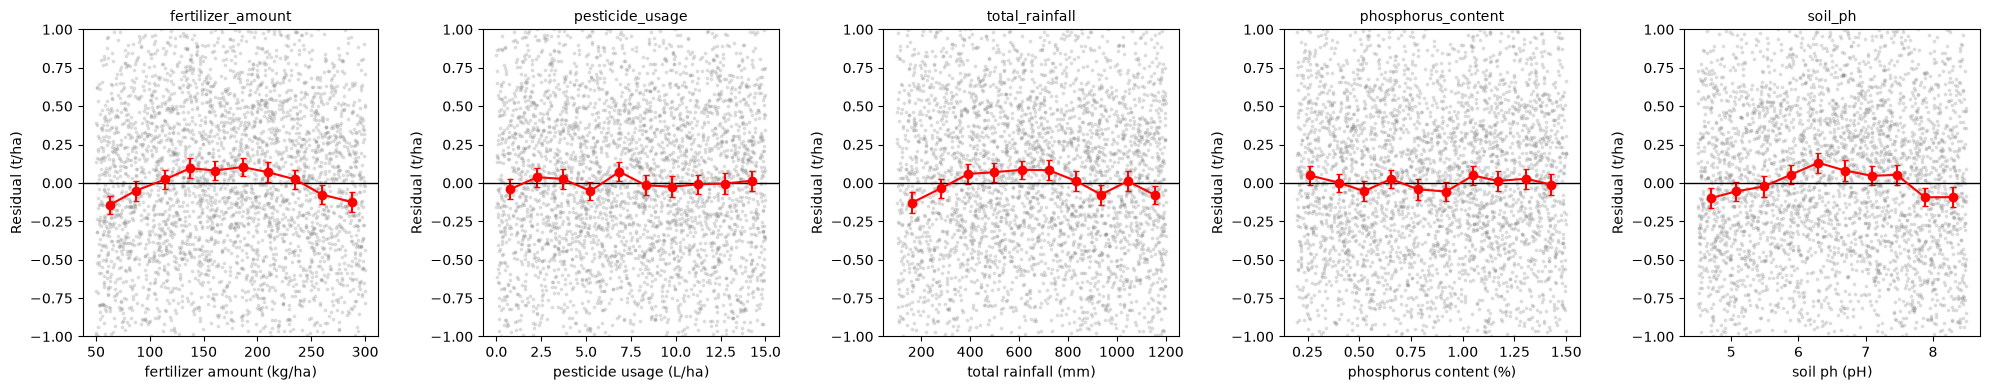

In [5]:
residual_features = list(train[config.NUMERIC_FEATURES].corrwith(y).abs().sort_values(ascending=False).index[:3])
signal = pd.read_csv(config.TABLES_DIR / "feature_signal.csv", index_col="feature")
curved = signal.index[signal["p_quadratic"] < ALPHA_LEVEL / len(config.NUMERIC_FEATURES)]
residual_features += [c for c in curved if c not in residual_features]
print("Features plotted:", residual_features)
fig, axes = plt.subplots(1, len(residual_features), figsize=(20, 4))
for ax, col in zip(axes, residual_features):
    b = binned_means(train[col], resid)
    ax.scatter(train[col], resid, s=3, alpha=0.2, color="grey")
    ax.errorbar(b["x_mid"], b["mean"], yerr=[b["mean"] - b["ci_low"], b["ci_high"] - b["mean"]], fmt="o-", color="red", capsize=2)
    ax.axhline(0, color="black", lw=1)
    ax.set(xlabel=axis_label(col), ylabel="Residual (t/ha)", ylim=(-1, 1))
    ax.set_title(col, fontsize=10)
save_figure(fig, "diag_residuals_vs_features")
for col in residual_features:
    b = binned_means(train[col], resid)
    print(f"{col:20s} binned mean residual range: {b['mean'].min():+.3f} to {b['mean'].max():+.3f} t/ha")

**Interpretation.** Residuals are zoomed to ±1 t/ha so the pattern is visible.
* `fertilizer_amount`, `total_rainfall` and `soil_ph` show a clear **∩ shape**:
  residuals are negative at both ends and positive in the middle. The straight
  line over-predicts at the extremes, i.e. **the linear model systematically
  misses diminishing returns (fertilizer, rainfall) and the pH optimum**.
* `pesticide_usage` (included as a linear control) is flat, as expected.
* `phosphorus_content`'s residual line stays within ≈ ±0.05 t/ha, the same as
  the non-curved pesticide control, so its U-shape from notebook 01 is **not
  distinguishable from noise** here. It is treated as weak evidence.

The misses are small, about ±0.1–0.14 t/ha at the extremes (printed above),
against a residual std of ≈ 0.64 t/ha. That is why the polynomial model gained
only ≈ 0.006 t/ha RMSE in Phase 4.

### Breusch-Pagan test for heteroscedasticity

In [6]:
bp_lm, bp_p, bp_f, bp_f_p = het_breuschpagan(resid, sm.add_constant(design))
print(f"Breusch-Pagan (out-of-fold residuals) LM statistic = {bp_lm:.3f}, p-value = {bp_p:.4f}")
ols_for_bp = sm.OLS(y, sm.add_constant(design)).fit()
bp_in = het_breuschpagan(ols_for_bp.resid, sm.add_constant(design))
print(f"Breusch-Pagan (textbook, in-sample OLS residuals) LM = {bp_in[0]:.3f}, p-value = {bp_in[1]:.4f}")

ols_hc3 = sm.OLS(y, sm.add_constant(design)).fit(cov_type="HC3")
if bp_p < ALPHA_LEVEL:
    ci3 = ols_hc3.conf_int()
    pd.DataFrame(
        {"coef": ols_hc3.params, "std_err": ols_hc3.bse, "p_value": ols_hc3.pvalues, "ci_low": ci3[0], "ci_high": ci3[1]}
    ).to_csv(config.TABLES_DIR / "ols_summary_hc3.csv", index_label="term")
    print("Heteroscedastic -> HC3 robust table saved.")
else:
    print("No evidence of heteroscedasticity -> classical OLS standard errors are kept.")
print(f"Largest relative change in a standard error with HC3: {(ols_hc3.bse / ols.bse - 1).abs().max():.1%}")

Breusch-Pagan (out-of-fold residuals) LM statistic = 21.816, p-value = 0.4102
Breusch-Pagan (textbook, in-sample OLS residuals) LM = 21.219, p-value = 0.4457
No evidence of heteroscedasticity -> classical OLS standard errors are kept.
Largest relative change in a standard error with HC3: 3.1%


**Interpretation.** Breusch-Pagan p is well above 0.05 → **no evidence that
the residual variance changes with the features** → the classical OLS standard
errors and p-values in section 2 are trustworthy (the textbook version on
in-sample OLS residuals agrees: LM ≈ 21.2, p ≈ 0.45), and the HC3 robust table is
not needed (as a cross-check, HC3 changes every standard error by only a few
percent, printed above). Why this matters: under heteroscedasticity, OLS
coefficients stay unbiased but their standard errors are wrong, so p-values and
confidence intervals would be misleading; HC3 errors remain valid in that case.

## 4. Lasso: coefficient path and selected features

CV-chosen alpha = 0.00290
Shrunk to exactly zero: ['crop_type_Corn', 'region_Central', 'region_East', 'region_West', 'season_Autumn', 'season_Spring']
Kept: 18 of 24


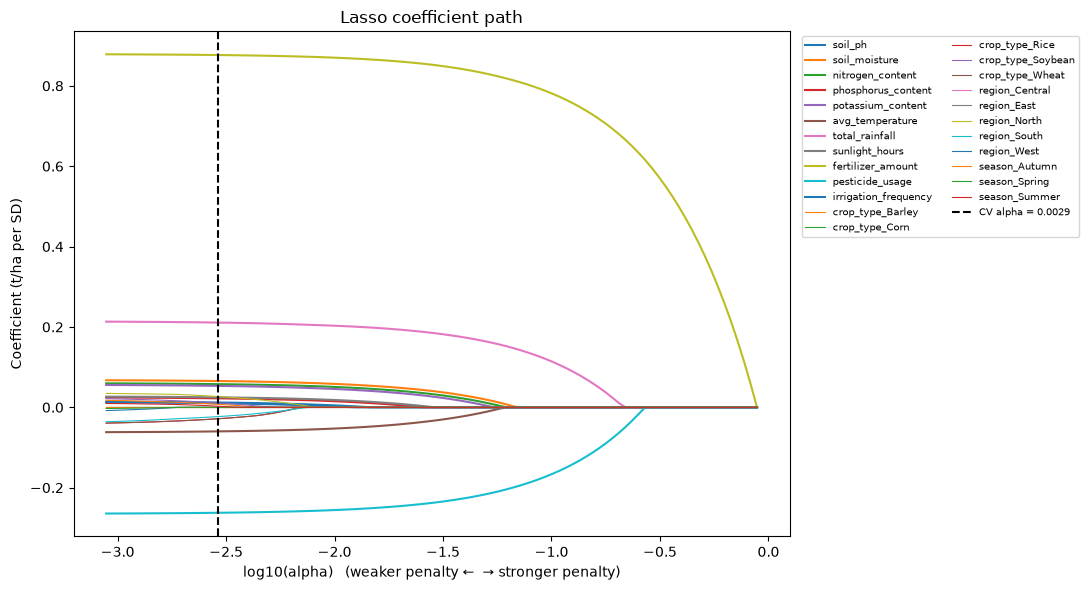

In [7]:
lasso = models["lasso"].fit(X, y)
lasso_design = transformed_frame(lasso[0], X)  # full one-hot (no dropped level)
Xc = lasso_design - lasso_design.mean()  # lasso_path fits no intercept, so centre X and y
yc = y - y.mean()
alphas, coefs, _ = lasso_path(Xc.to_numpy(), yc.to_numpy(), alphas=100)
fig, ax = plt.subplots(figsize=(11, 6))
for i, name in enumerate(lasso_design.columns):
    ax.plot(np.log10(alphas), coefs[i], lw=1.5 if name in config.NUMERIC_FEATURES else 0.8, label=name)
ax.axvline(np.log10(lasso[-1].alpha_), color="black", ls="--", label=f"CV alpha = {lasso[-1].alpha_:.4f}")
ax.set(xlabel="log10(alpha)   (weaker penalty ←  → stronger penalty)", ylabel="Coefficient (t/ha per SD)", title="Lasso coefficient path")
ax.legend(fontsize=7, ncol=2, bbox_to_anchor=(1.01, 1), loc="upper left")
save_figure(fig, "diag_lasso_path")

lasso_coef = pd.Series(lasso[-1].coef_, index=lasso_design.columns)
print(f"CV-chosen alpha = {lasso[-1].alpha_:.5f}")
print("Shrunk to exactly zero:", list(lasso_coef[lasso_coef == 0].index))
print("Kept:", int((lasso_coef != 0).sum()), "of", len(lasso_coef))

**Interpretation.** Reading the path from right (strong penalty) to left (weak
penalty) shows the order in which features enter the model: `fertilizer_amount`
enters first, then `pesticide_usage`, then `total_rainfall`, then the small
soil and temperature effects (soil moisture, nitrogen, potassium,
avg_temperature). The categorical dummies enter last and stay near zero. The
CV-chosen alpha is very small. That is not because the data are noise-free
(residual σ ≈ 0.64 t/ha): with 3,840 rows, only 24 terms and uncorrelated
features, the unpenalised fit barely over-fits, so shrinkage has little
variance to remove. At that alpha Lasso keeps **all 11 numeric features**
and zeroes out only crop/region/season dummies (listed above). Lasso's
verdict: every measured numeric variable carries some linear signal; the
context variables carry essentially none.

## 5. Simple vs multiple linear regression

In [8]:
cv_linear = pd.read_csv(config.TABLES_DIR / "cv_linear.csv").set_index("model")
r2_simple, r2_multiple = cv_linear.loc["simple_lr", "r2_mean"], cv_linear.loc["multiple_lr", "r2_mean"]
print(f"simple_lr ({simple_feature}) CV R² = {r2_simple:.3f}")
print(f"multiple_lr (all features)  CV R² = {r2_multiple:.3f}")
print(f"Share of multiple_lr's explained variance captured by {simple_feature} alone: {r2_simple / r2_multiple:.1%}")

simple_lr (fertilizer_amount) CV R² = 0.591
multiple_lr (all features)  CV R² = 0.690
Share of multiple_lr's explained variance captured by fertilizer_amount alone: 85.7%


**Interpretation.** Fertilizer alone explains ≈ 59 % of yield variance (CV),
and all features together ≈ 69 %: **the single best feature captures ≈ 86 % of
what the full linear model explains.** The other 13 features together add only
≈ 10 percentage points of R². Yield in this dataset is essentially a fertilizer
story with modest adjustments from pesticide and rainfall.

## Summary

| Diagnostic | Result | Meaning |
|---|---|---|
| VIF | all ≈ 1.00 | no multicollinearity; coefficients individually interpretable |
| OLS | R² ≈ 0.69; fertilizer +0.88, pesticide −0.27, rainfall +0.21 t/ha per SD | large farming + weather effects, context ≈ 0 |
| Residuals | normal, zero-mean, constant spread | OLS assumptions hold |
| Residuals vs features | small ∩-shaped misses for fertilizer, rainfall, pH (≈ ±0.1 t/ha); phosphorus ≈ noise | linear model misses mild curvature |
| Breusch-Pagan | p > 0.05 | homoscedastic → classical SEs valid, HC3 not needed |
| Lasso | keeps all 11 numeric, zeroes some context dummies | context variables carry no signal |
| Simple vs multiple | fertilizer alone ≈ 86 % of multiple_lr's R² | one dominant driver |